In [22]:
%run general.ipynb
%matplotlib inline
RESULTS_DIR = '../results'
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f'Output directory: {RESULTS_DIR}')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
2026-05-15 19:57:26 WARNING These have metadata but do not have data - dropped (415): {'BLANK6.6H', 'H3.skin.TE.09.14.15.1p.glass.4', 'BLANK8.7B', 'BLANK.3.D3', 'H3.skin.TE.09.14.15.11a.glass.5', 'H5.skin.TE.09.14.15.3p.glass.2', 'surface.ctrl.TE.12.18.15.ceramic.1', 'H2.skin.TE.09.14.15.1p.glass.1', 'H3.skin.TE.09.14.15.11a.metal.4', 'H1.skin.TE.09.14.15.3p.metal.4', 'BLANK13.6.6H', 'BLANK13.6.6G', 'surface.ctrl.9.11.17.plastic.1sec.5', 'BLANK8.9F', 'BLANK.4.D8', 'H1.skin.TE.09.14.15.3p.metal.3', 'H1.skin.TE.09.14.15.11a.plastic.4', 'BLANK8.4E', 'BLANK8.12E', 'H4.surface.10x.TE.12.15.15.plastic.5', 'BLANK13.1.1H', 'H5.skin.TE.09.14.15.3p.glass.1', 'BLANK.4.G8', 'BLANK8.10D', 'BLANK6.6A', 'surface.ctrl.9.11.17.plastic.1sec.4', 'H3.skin.TE.09.14.15.1p.plastic.4', 'BLANK8.8F', 'BLANK8.3B', 'BLANK12.B10', 'BLANK13.4.5G', 'H4.skin.TE.09.14.15.1p.glass.2', 'surface.ctrl.9.12.17.plastic.1day.6', 'BLANK.3.

### Part 1: Individual Identification by **Material Type**

This is the first core experiment, testing whether the model can identify individuals based on microbes on different materials (ceramic, glass, metal, etc.).

In [23]:
metadata_filtered = exp.sample_metadata
hosts_on_surfaces = set(metadata_filtered.query('experiment_category=="material_type" & sample_type=="surface_touched"')['individual'].unique())
skin_sample_counts = metadata_filtered.query('sample_type=="skin"')['individual'].value_counts()
skin_sample_counts = skin_sample_counts[skin_sample_counts >= 3]
hosts_with_skin_samples = set(skin_sample_counts.index)
common_hosts = list(hosts_on_surfaces.intersection(hosts_with_skin_samples))

print(f"Number of common hosts found: {len(common_hosts)}")
print(f"Common hosts: {common_hosts}")

Number of common hosts found: 24
Common hosts: ['H10', 'H3', 'H43', 'H46', 'H4', 'H44', 'H7', 'H1', 'H48', 'H6', 'H18', 'H5', 'H20', 'H8', 'H39', 'H33', 'H38', 'H47', 'H40', 'H45', 'H2', 'H42', 'H9', 'H41']


In [24]:
exp_material_type = (exp.filter_samples('individual', common_hosts)
                      .filter_samples('experiment_category', 'material_type')
                      .filter_samples('sample_type', ['skin', 'surface_touched']))
exp_material_type

AmpliconExperiment ("reference-hit.2026.biom") with 804 samples, 10511 features

In [25]:
exp_material_type.filter_samples('sample_type', 'skin').sample_metadata['individual'].value_counts()

individual
H40    13
H39    12
H38    10
H2     10
H4     10
H18    10
H5     10
H1     10
H8      7
H44     5
H47     5
H41     5
H46     5
H45     5
H48     5
H42     5
H7      5
H20     5
H3      5
H10     5
H6      5
H9      5
H43     5
H33     3
Name: count, dtype: int64

In [26]:
train_set = exp_material_type.filter_samples('sample_type', 'skin').filter_by_metadata('_calour_original_abundance', select=lambda i: i > 500).downsample(
    'individual', num_keep=3, random_state=0)
print("Training set details:")
train_set

Training set details:


AmpliconExperiment ("reference-hit.2026.biom") with 72 samples, 10511 features

In [27]:
test_set = (exp_material_type.filter_samples('sample_type', 'surface_touched')
                             .filter_samples('experiment_category', 'material_type')
                             .filter_samples('individual', train_set.sample_metadata.individual.unique().tolist())
                             .filter_ids(train_set.feature_metadata.index, axis=1)
                             .filter_by_metadata('_calour_original_abundance', select=lambda i: i > 200))
print("Test set details:")
test_set


Test set details:


AmpliconExperiment ("reference-hit.2026.biom") with 561 samples, 10511 features

In [28]:
grid_search_material_type = make_rf_grid_search()

In [29]:
# Load or Run Grid Search ---
saved_model_path = os.path.join(RESULTS_DIR, 'material-type-combined.pkl.bz2')
best_model_material_type = load_or_fit_model(grid_search_material_type, saved_model_path, train_set.data, train_set.sample_metadata.individual)

Loading pre-trained model from ../results/material-type-combined.pkl.bz2...


In [30]:
y_pred_material = best_model_material_type.predict(test_set.data)

# Calculate prediction probabilities for each sample
prediction_probabilities = pd.DataFrame(best_model_material_type.predict_proba(test_set.data),
                                      columns=best_model_material_type.classes_,
                                      index=test_set.sample_metadata.index)
prediction_probabilities.index.name = 'samples'
prediction_probabilities.columns.name = 'individuals'

# Save prediction probability matrix
prediction_probabilities.to_csv(os.path.join(RESULTS_DIR, 'material-type-prob.tsv'), sep='\t')

# Convert prediction probabilities to ranks
probability_ranks = prediction_probabilities.rank(axis=1, ascending=False)


In [31]:
jk_cache_path = os.path.join(RESULTS_DIR, 'material-type-jackknife.pkl.bz2')
material_order = ['plastic', 'ceramic', 'wood', 'glass',  'metal']
REFRESH_CACHE = True

test_jk = test_set.filter_samples('touches', '10')
test_jk.sample_metadata['replicate_order'] = test_jk.sample_metadata['replicate_order'].astype(int)
touch_orders_unique = sorted(test_jk.sample_metadata['replicate_order'].unique())
material_to_i = {m: i for i, m in enumerate(material_order)}
rep_to_j = {r: j for j, r in enumerate(touch_orders_unique)}

def material_jk_contrib(md, **ctx):
    mat_i = material_to_i.get(md['surface_type'], -1)
    rep_j = rep_to_j.get(md['replicate_order'], -1)
    if mat_i < 0 or rep_j < 0:
        return []
    return [{
        'group_index': (mat_i, rep_j),
        'target': md['individual'],
    }]

rep1_idx = rep_to_j.get(1, 0)
jackknife_results = compute_cached_jackknife_tensor(
    model=best_model_material_type,
    X=test_jk.data,
    sample_metadata=test_jk.sample_metadata,
    contribution_getter=material_jk_contrib,
    class_labels=best_model_material_type.classes_,
    max_N=24,
    progress_every=100,
    tensor_shape=(len(material_order), len(touch_orders_unique)),
    cache_path=jk_cache_path,
    force_refresh=REFRESH_CACHE,
    topn_getter=lambda jk_result: jk_result['jk_bar'][:, :, :, rep1_idx].copy(),
    cache_extras={
        'material_order': material_order,
        'touch_orders': touch_orders_unique,
    },
)

jk_bar = jackknife_results['jk_bar']
jk_topn = jackknife_results['jk_topn']
material_order = jackknife_results.get('material_order', material_order)
touch_orders_unique = jackknife_results.get('touch_orders', touch_orders_unique)


Running jackknife on test set...
   Progress: 100/422
   Progress: 200/422
   Progress: 300/422
   Progress: 400/422
Jackknife results saved.


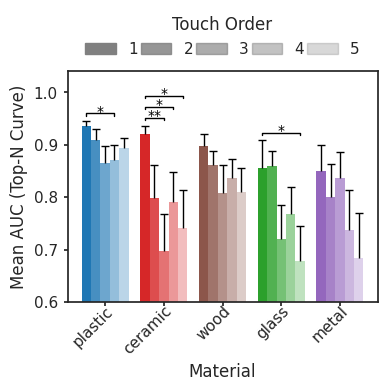

In [32]:
init_plot_style()
material_order = ['plastic', 'ceramic', 'wood', 'glass', 'metal']
mat_color_dict = MAT_COLOR_DICT

df_auc = summarize_auc_grid(
    sample_metadata=test_jk.sample_metadata,
    fold_tensor=jk_bar,
    row_order=material_order,
    col_order=touch_orders_unique,
    row_metadata='surface_type',
    col_metadata='replicate_order',
    row_name='material',
    col_name='touch_order',
)

fig_auc, ax_auc = plt.subplots(figsize=(4, 3))
fig_auc.patch.set_facecolor('white')
ax_auc.set_facecolor('white')

sns.barplot(
    x='material', y='auc', hue='touch_order',
    data=df_auc, order=material_order, hue_order=touch_orders_unique,
    ax=ax_auc, linewidth=0,
)

ax_auc.set_ylabel('Mean AUC (Top-N Curve)', fontsize=12)
ax_auc.set_xlabel('Material', fontsize=12)

handles, labels = ax_auc.get_legend_handles_labels()
n_touch_orders = len(labels)
alphas = np.linspace(1.0, 0.3, n_touch_orders)
coords_info = {}

for i, patch in enumerate(ax_auc.patches):
    touch_idx = i // len(material_order)
    mat_idx = i % len(material_order)
    mat_name = material_order[mat_idx]
    rep_val = touch_orders_unique[touch_idx]

    patch.set_facecolor(mat_color_dict[mat_name])
    patch.set_alpha(alphas[touch_idx])
    patch.set_linewidth(0)
    patch.set_edgecolor('none')

    x_center = patch.get_x() + patch.get_width() / 2
    row = df_auc[
        (df_auc['material'] == mat_name) &
        (df_auc['touch_order'] == rep_val)
    ]
    if row.empty:
        continue

    y_val = row['auc'].iloc[0]
    y_err = row['error'].iloc[0]
    n_val = row['n_sub'].iloc[0]

    add_manual_errorbars(
        ax_auc,
        x_center,
        y_val,
        lower_errors=0,
        upper_errors=y_err,
        hide_lower_caps=True,
    )
    coords_info[(mat_name, rep_val)] = {
        'x': x_center,
        'y': y_val,
        'err': y_err,
        'n': n_val,
    }

global_max_y = float(df_auc['auc'].max() + df_auc['error'].max())
baseline_order = 1

for mat_name in material_order:
    mat_orders = [rep for rep in touch_orders_unique if (mat_name, rep) in coords_info]
    if baseline_order not in mat_orders:
        continue

    mat_max_y = max(
        coords_info[(mat_name, rep)]['y'] + coords_info[(mat_name, rep)]['err']
        for rep in mat_orders
    )
    result = annotate_pairwise_bar_significance(
        ax_auc,
        coords_info,
        baseline_key=(mat_name, baseline_order),
        compare_keys=[(mat_name, rep) for rep in mat_orders if rep != baseline_order],
        line_y_start=mat_max_y + 0.01,
        line_step=0.021,
        hook_height=0.005,
        text_offset=-0.01,
    )
    if result['global_max_y'] is not None:
        global_max_y = max(global_max_y, result['global_max_y'])

custom_handles = [mpatches.Patch(color='gray', alpha=a) for a in alphas]
ax_auc.legend(
    handles=custom_handles, labels=labels,
    loc='center', bbox_to_anchor=(.5, 1.15), columnspacing=0.2,
    ncol=n_touch_orders, title='Touch Order', frameon=False,
)

ax_auc.set_ylim(0.6, max(1.0, global_max_y + 0.02))
ax_auc.spines['top'].set_visible(True)
ax_auc.spines['right'].set_visible(True)
ax_auc.spines['bottom'].set_visible(True)
ax_auc.spines['left'].set_visible(True)
ax_auc.grid(False)
ax_auc.tick_params(axis='x', bottom=True, length=3, pad=-2)
ax_auc.tick_params(axis='y', left=True, length=3, pad=4)
rotate_xticklabels(ax_auc)
plt.show()


In [33]:
d = RESULTS_DIR
save_fig(fig_auc, os.path.join(d, 'material-type-auc.pdf'))


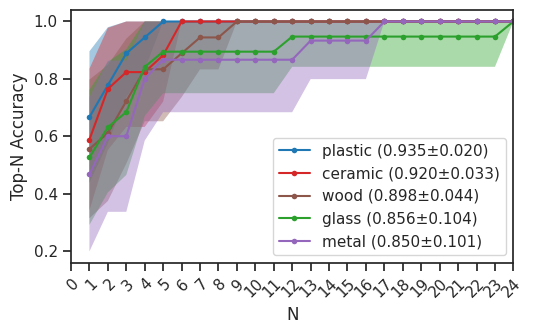

In [34]:
import os
import numpy as np
import matplotlib.pyplot as plt

fig_topn_jk, ax_topn_jk, curves, bracket_info = plot_group_topn_jackknife(
    jk_topn=jk_topn,
    sample_metadata=test_jk.sample_metadata,
    group_order=['plastic', 'ceramic', 'wood', 'glass', 'metal'],
    axis_order=material_order,
    metadata_col='surface_type',
    baseline_group='plastic',
    color_dict=MAT_COLOR_DICT,
    save_path=os.path.join(RESULTS_DIR, 'material-type-jackknife-top-N.pdf'),
)


In [35]:
metadata_dist_analysis = metadata_filtered.query('experiment_category=="material_type"& touches in ["skin", "10"] & replicate_order not in [2,3,4,5]')
sample_ids_for_dist = metadata_dist_analysis.index
print(f"Number of samples for distance analysis: {len(sample_ids_for_dist)}")

beta_diversity_matrix = read('../data/extracted_qza/weighted_unifrac_distance_matrix/8d668add-c00f-4e13-8800-cad9e89d022c/data/distance-matrix.tsv', format='lsmat', into=DistanceMatrix)

beta_diversity_filtered = beta_diversity_matrix.filter(sample_ids_for_dist, strict=False)

Number of samples for distance analysis: 301


In [36]:
# Initialize a dictionary to store sample pairs based on comparison type (e.g., within-individual, between-individuals, skin-vs-skin, skin-vs-material).
pair_categories = {
    'skin_vs_skin_within': [], 'skin_vs_skin_across': [],
    'skin_vs_ceramic_within': [], 'skin_vs_ceramic_across': [],
    'skin_vs_glass_within': [], 'skin_vs_glass_across': [],
    'skin_vs_wood_within': [], 'skin_vs_wood_across': [],
    'skin_vs_plastic_within': [], 'skin_vs_plastic_across': [],
    'skin_vs_metal_within': [], 'skin_vs_metal_across': []
}

In [37]:
# Iterate through all unique sample pairs and classify them based on predefined categories.
for row1, row2 in itertools.combinations(metadata_dist_analysis.itertuples(), 2):
    # Case 1: Comparing two skin samples
    if row1.sample_type == 'skin' and row2.sample_type == 'skin':
        if row1.individual == row2.individual:
            pair_categories['skin_vs_skin_within'].append([row1.Index, row2.Index])
        else:
            pair_categories['skin_vs_skin_across'].append([row1.Index, row2.Index])
    # Case 2: Comparing a skin sample to a touched surface sample
    elif row1.sample_type == 'skin' or row2.sample_type == 'skin':
        surface_type = row2.surface_type if row1.sample_type == 'skin' else row1.surface_type
        if not isinstance(surface_type, str):
            continue
        
        comparison_type = 'within' if row1.individual == row2.individual else 'across'
        key = f'skin_vs_{surface_type}_{comparison_type}'
        
        if key in pair_categories:
            pair_categories[key].append([row1.Index, row2.Index])

In [38]:
distance_data = []
for category, pairs_list in pair_categories.items():
    for pair in pairs_list:
        if pair[0] in beta_diversity_filtered.ids and pair[1] in beta_diversity_filtered.ids:
            distance = beta_diversity_filtered[pair[0], pair[1]]
            distance_data.append([category, distance, pair[0], pair[1]])

distances_df = pd.DataFrame(distance_data, columns=['type', 'distance', 'sample1', 'sample2'])

In [39]:
distances_df[['type', 'group']] = distances_df['type'].str.rsplit('_', n=1, expand=True)

In [40]:
p_values = {}
print("Permutation Test Results (p-value, test-statistic):")
for comparison_type in distances_df.type.unique():
    within_group = distances_df.query('(type==@comparison_type) & (group=="within")')
    across_group = distances_df.query('(type==@comparison_type) & (group=="across")')
    
    result = distance_permute_test(beta_diversity_filtered, 
                                   across_group[['sample1','sample2']].values.tolist(), 
                                   within_group[['sample1','sample2']].values.tolist())
    p_values[comparison_type] = result[0]
    print(f"{comparison_type}: p-value={result[0]}, test-statistic={result[1]}")

Permutation Test Results (p-value, test-statistic):
skin_vs_skin: p-value=0.0, test-statistic=-0.09088873841004386
skin_vs_ceramic: p-value=0.0, test-statistic=-0.06545024350684692
skin_vs_glass: p-value=0.0, test-statistic=-0.05908537586759588
skin_vs_wood: p-value=0.0, test-statistic=-0.06535601941863528
skin_vs_plastic: p-value=0.0, test-statistic=-0.10637526015076237
skin_vs_metal: p-value=0.0, test-statistic=-0.06916005642458956


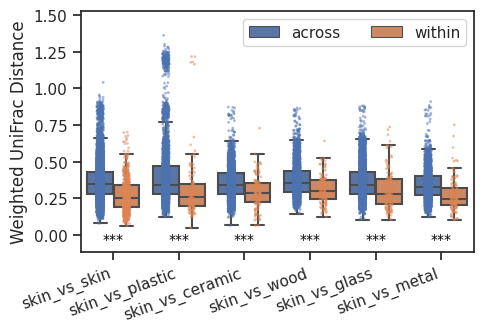

In [41]:
init_plot_style()

fig_beta_diversity, ax_beta_diversity = plt.subplots(figsize=(5, 3.5))
plot_order = ['skin_vs_skin', 'skin_vs_plastic','skin_vs_ceramic', 'skin_vs_wood',  'skin_vs_glass','skin_vs_metal' ]
hue_order = ['across', 'within']

sns.boxplot(x='type', y='distance', hue='group', 
            order=plot_order, hue_order=hue_order, 
            data=distances_df, ax=ax_beta_diversity,
            fliersize=0)

sns.stripplot(x='type', y='distance', hue='group', 
              order=plot_order, hue_order=hue_order, 
              data=distances_df, ax=ax_beta_diversity,
              dodge=True, 
              size=2, 
              jitter=True,  
              alpha=0.5)     
y_min_val = distances_df['distance'].min()

for i, comparison_type in enumerate(plot_order):
    p_val = p_values.get(comparison_type)
    if p_val is not None:
        sig = get_significance_stars(p_val, non_sig='n.s.')
        
        ax_beta_diversity.text(i, y_min_val - 0.03, sig, 
                               ha='center', va='top', color='black', fontsize=10)

ax_beta_diversity.set_ylabel('Weighted UniFrac Distance')
ax_beta_diversity.set_xlabel('')
fig_beta_diversity.autofmt_xdate(rotation=20, ha='right')

handles, labels = ax_beta_diversity.get_legend_handles_labels()
n_categories = len(hue_order) 
ax_beta_diversity.legend(handles[:n_categories], labels[:n_categories], 
                         loc='upper right', ncol=2)

ax_beta_diversity.set_ylim(top=ax_beta_diversity.get_ylim()[1] + 0.1, 
                           bottom=ax_beta_diversity.get_ylim()[0] - 0.1)

fig_beta_diversity.tight_layout()
plt.show()

In [42]:
d = RESULTS_DIR
save_fig(fig_beta_diversity, os.path.join(d, 'material-combined-weighted-unifrac.pdf'))